# Notebook 10: Portfolio Optimization with Modern Portfolio Theory

**Project:** Factor Investing and Portfolio Optimization in Indian Markets  
**Universe:** RELIANCE, TCS, INFOSYS, HDFC Bank, and ICICI Bank  
**Period:** January 2020–December 2025

## Objective

This notebook applies constrained mean-variance portfolio optimization and compares optimized portfolios with an equal-weight benchmark. To reduce look-ahead bias, portfolio weights are estimated on a training sample and evaluated on a later, out-of-sample period.

### Portfolios
1. **Equal weight:** a simple baseline with the same allocation to each stock.
2. **Global minimum variance:** minimizes estimated portfolio variance.
3. **Maximum Sharpe:** maximizes estimated excess return per unit of volatility.
4. **Efficient frontier:** illustrates the risk-return trade-off among feasible long-only portfolios.

### Modeling choices
- Adjusted prices are used through `yfinance`'s `auto_adjust=True` option.
- Daily returns are used to estimate annualized mean returns and covariance.
- Portfolios are long-only and fully invested, so weights sum to one.
- Optimization uses training data only; performance metrics use the held-out test period.
- The out-of-sample calculation assumes the estimated weights are maintained as a constant-mix portfolio. Transaction costs, taxes, and market impact are not included.

> This is an educational research experiment with a five-stock universe, not investment advice or evidence of market-wide outperformance.

## 1. Setup and reproducibility

Install any missing packages in the environment where this notebook is run. The notebook records the main assumptions in one place so they can be changed consistently.

In [1]:
# If needed in Colab, uncomment:
# %pip install -q yfinance scipy seaborn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.optimize import minimize
from IPython.display import display

SEED = 42
TRADING_DAYS = 252
START_DATE = "2020-01-01"
END_DATE = "2026-01-01"  # exclusive
TRAIN_END = "2023-12-31"
TEST_START = "2024-01-01"

TICKERS = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS",
]

ASSET_NAMES = {
    "RELIANCE.NS": "Reliance",
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "HDFCBANK.NS": "HDFC Bank",
    "ICICIBANK.NS": "ICICI Bank",
}

np.random.seed(SEED)
print("Configuration loaded.")
print(f"Universe: {', '.join(ASSET_NAMES[t] for t in TICKERS)}")

Configuration loaded.
Universe: Reliance, TCS, Infosys, HDFC Bank, ICICI Bank


## 2. Download adjusted price data

We use `auto_adjust=True`, which adjusts the OHLC price series for splits and dividends. We retain dates where all five assets have valid prices to keep portfolio calculations aligned.

In [2]:
# Download each ticker separately to avoid concurrent yfinance/cache database locks.
# If a ticker fails transiently, retry it before stopping the notebook.
import time

price_series = {}
download_errors = {}

for ticker in TICKERS:
    ticker_data = None
    last_error = None

    for attempt in range(1, 4):
        try:
            ticker_raw = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                auto_adjust=True,
                progress=False,
                threads=False,
            )

            if ticker_raw.empty:
                raise RuntimeError("Yahoo Finance returned an empty dataset.")

            if isinstance(ticker_raw.columns, pd.MultiIndex):
                if "Close" in ticker_raw.columns.get_level_values(0):
                    close_data = ticker_raw["Close"]
                    close_series = close_data.iloc[:, 0] if isinstance(close_data, pd.DataFrame) else close_data
                elif "Close" in ticker_raw.columns.get_level_values(1):
                    close_data = ticker_raw.xs("Close", axis=1, level=1)
                    close_series = close_data.iloc[:, 0] if isinstance(close_data, pd.DataFrame) else close_data
                else:
                    raise KeyError("Could not find the Close field in downloaded data.")
            else:
                if "Close" not in ticker_raw.columns:
                    raise KeyError("Could not find the Close field in downloaded data.")
                close_series = ticker_raw["Close"]

            close_series = pd.to_numeric(close_series, errors="coerce").dropna()
            if close_series.empty:
                raise RuntimeError("No valid closing prices were returned.")

            price_series[ticker] = close_series.rename(ticker)
            ticker_data = close_series
            break

        except Exception as exc:
            last_error = exc
            if attempt < 3:
                print(f"{ticker}: download attempt {attempt} failed ({exc}); retrying...")
                time.sleep(2 * attempt)

    if ticker_data is None:
        download_errors[ticker] = repr(last_error)

if download_errors:
    raise RuntimeError(
        "Could not download prices for these tickers after 3 attempts: "
        + str(download_errors)
        + ". Wait briefly and rerun this cell; also check that the Colab runtime has internet access."
    )

prices = pd.concat(price_series.values(), axis=1).sort_index()
prices = prices.reindex(columns=TICKERS)
prices = prices.loc[~prices.index.duplicated(keep="first")].dropna(how="any")

if prices.empty:
    raise RuntimeError("No complete price rows remain after cleaning. At least one ticker may have insufficient overlapping data.")

display(prices.head())
print(f"Price observations: {len(prices):,}")
print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()}")


,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216125,1821.426880,619.740417,595.677185,514.797913
2020-01-02,683.660217,1813.065918,617.931946,599.474182,518.490417
2020-01-03,684.484070,1849.198730,627.436096,590.925232,516.811951
2020-01-06,668.609314,1849.030396,621.422424,578.136719,504.199921
2020-01-07,678.895691,1853.568237,612.212891,587.291382,501.514343


Price observations: 1,487
Date range: 2020-01-01 to 2025-12-31


## 3. Inspect prices, returns, and correlations

Daily simple returns are computed as percentage changes. The training sample is used for optimization; the test sample is held aside for evaluation.

Training observations: 991 (2020-01-02 to 2023-12-29)
Test observations: 495 (2024-01-01 to 2025-12-31)


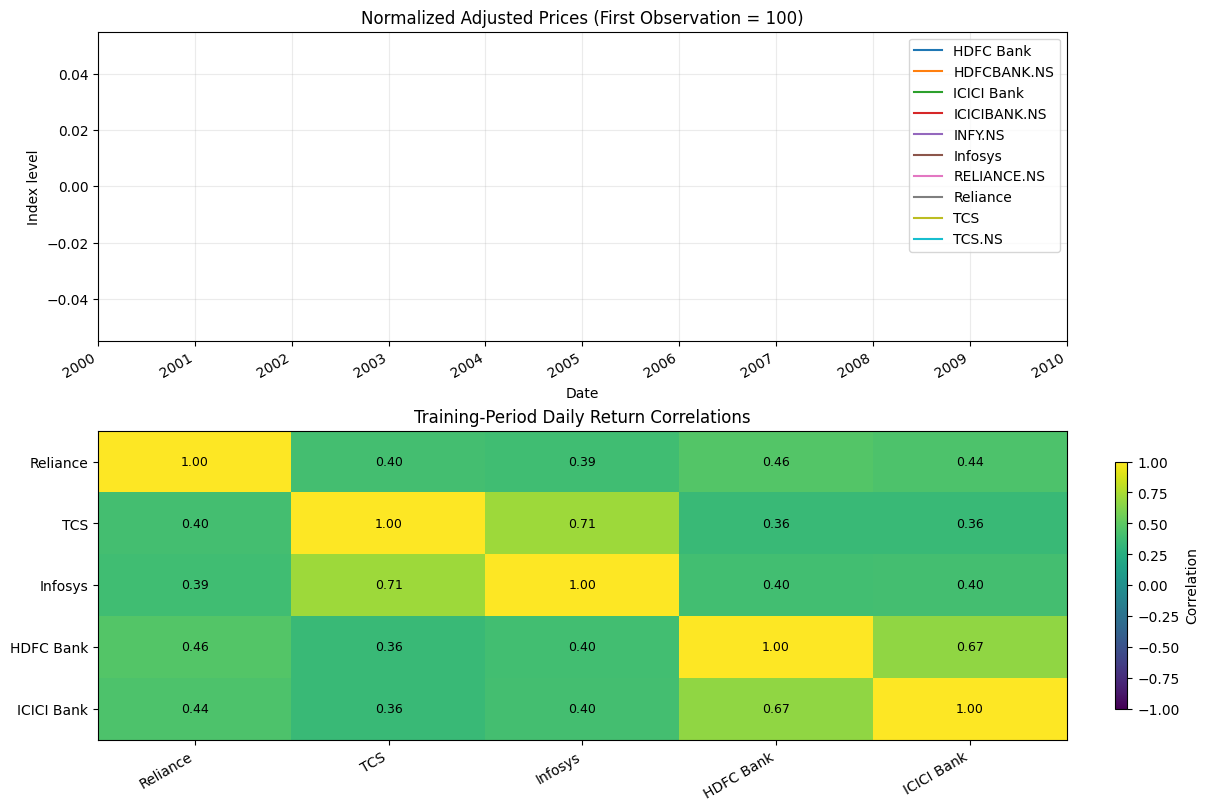

In [3]:
returns = prices.pct_change().replace([np.inf, -np.inf], np.nan).dropna()
returns = returns.rename(columns=ASSET_NAMES)

train_returns = returns.loc[:TRAIN_END].copy()
test_returns = returns.loc[TEST_START:].copy()

if len(train_returns) < 252:
    raise ValueError("Training sample is shorter than one trading year. Check downloaded dates.")
if test_returns.empty:
    raise ValueError("Test sample is empty. Check TEST_START and the downloaded date range.")

print(f"Training observations: {len(train_returns):,} ({train_returns.index.min().date()} to {train_returns.index.max().date()})")
print(f"Test observations: {len(test_returns):,} ({test_returns.index.min().date()} to {test_returns.index.max().date()})")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
(prices.rename(columns=ASSET_NAMES).div(prices.iloc[0]).mul(100)).plot(ax=axes[0])
axes[0].set_title("Normalized Adjusted Prices (First Observation = 100)")
axes[0].set_ylabel("Index level")
axes[0].grid(alpha=0.25)

corr = train_returns.corr()
im = axes[1].imshow(corr, vmin=-1, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(corr.columns)), corr.columns, rotation=30, ha="right")
axes[1].set_yticks(range(len(corr.index)), corr.index)
axes[1].set_title("Training-Period Daily Return Correlations")
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes[1], shrink=0.8, label="Correlation")
plt.show()

## 4. Estimate annualized inputs

For daily mean returns $$(\mu_d)$$ and daily covariance matrix $$(\Sigma_d),$$ the standard annualized estimates are:

$$
\mu_{\text{ann}} = 252\mu_d,\qquad
\Sigma_{\text{ann}} = 252\Sigma_d.
$$

For weights \(w\), expected return and volatility are:

$$
E[R_p] = w^\top \mu_{\text{ann}},\qquad
\sigma_p = \sqrt{w^\top \Sigma_{\text{ann}}w}.
$$

These estimates can be noisy, especially expected returns. Treat optimized weights as estimates that need robustness checks, not as exact answers.

In [4]:
mu_daily = train_returns.mean()
cov_daily = train_returns.cov()

mu_annual = mu_daily * TRADING_DAYS
cov_annual = cov_daily * TRADING_DAYS

asset_estimates = pd.DataFrame({
    "Annualized Mean Return": mu_annual,
    "Annualized Volatility": np.sqrt(np.diag(cov_annual)),
})
display(asset_estimates.style.format({
    "Annualized Mean Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
}))

,Annualized Mean Return,Annualized Volatility
Reliance,21.17%,31.20%
TCS,19.42%,25.24%
Infosys,25.32%,28.97%
HDFC Bank,12.10%,28.36%
ICICI Bank,21.97%,33.93%


## 5. Define portfolio statistics and constraints

We use long-only weights in the interval [0, 1] and require the weights to sum to one. The risk-free rate is an explicit assumption for the maximum-Sharpe calculation and can be changed.

In [5]:
RISK_FREE_RATE = 0.06  # annual assumption; change if justified for your study
N_ASSETS = len(mu_annual)
BOUNDS = tuple((0.0, 1.0) for _ in range(N_ASSETS))
CONSTRAINTS = ({"type": "eq", "fun": lambda w: np.sum(w) - 1.0},)
INITIAL_WEIGHTS = np.repeat(1 / N_ASSETS, N_ASSETS)

def portfolio_return(weights, mean_returns=mu_annual):
    return float(np.dot(weights, mean_returns))

def portfolio_volatility(weights, covariance=cov_annual):
    variance = float(np.dot(weights, np.dot(covariance, weights)))
    return float(np.sqrt(max(variance, 0.0)))

def portfolio_sharpe(weights, mean_returns=mu_annual, covariance=cov_annual,
                     risk_free_rate=RISK_FREE_RATE):
    vol = portfolio_volatility(weights, covariance)
    if vol <= 1e-12:
        return np.nan
    return (portfolio_return(weights, mean_returns) - risk_free_rate) / vol

def optimize_objective(objective, initial=INITIAL_WEIGHTS):
    result = minimize(
        objective,
        x0=initial,
        method="SLSQP",
        bounds=BOUNDS,
        constraints=CONSTRAINTS,
        options={"maxiter": 2000, "ftol": 1e-12},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    # Remove tiny numerical negatives and normalize.
    weights = np.clip(result.x, 0.0, 1.0)
    weights = weights / weights.sum()
    return weights, result

## 6. Optimize portfolios

- **Minimum variance** minimizes annualized variance.
- **Maximum Sharpe** maximizes the estimated Sharpe ratio using the chosen risk-free-rate assumption.
- **Equal weight** is retained as a transparent baseline.

Because both optimizers use training-period estimates only, the held-out test period remains available for an out-of-sample comparison.

In [6]:
equal_weights = INITIAL_WEIGHTS.copy()

min_var_weights, min_var_result = optimize_objective(
    lambda w: float(w @ cov_annual.values @ w)
)

max_sharpe_weights, max_sharpe_result = optimize_objective(
    lambda w: -portfolio_sharpe(w)
)

weight_table = pd.DataFrame({
    "Equal Weight": equal_weights,
    "Minimum Variance": min_var_weights,
    "Maximum Sharpe": max_sharpe_weights,
}, index=mu_annual.index)

display(weight_table.style.format("{:.2%}"))
print("Weight sums:")
display(weight_table.sum(axis=0).to_frame("Sum").style.format("{:.6f}"))

,Equal Weight,Minimum Variance,Maximum Sharpe
Reliance,20.00%,16.12%,21.99%
TCS,20.00%,44.58%,4.95%
Infosys,20.00%,7.50%,56.61%
HDFC Bank,20.00%,29.77%,0.00%
ICICI Bank,20.00%,2.02%,16.46%


Weight sums:


,Sum
Equal Weight,1.000000
Minimum Variance,1.000000
Maximum Sharpe,1.000000


## 7. Plot the efficient frontier

For each target return between the lowest and highest estimated individual-asset mean returns, minimize variance subject to achieving that target return and maintaining the long-only, fully invested constraints. This is an estimated frontier based on training data.

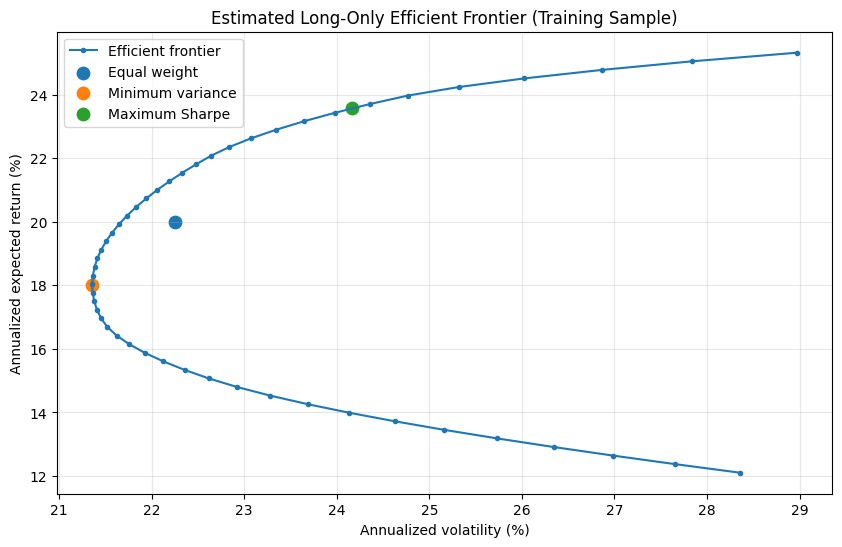

In [7]:
target_returns = np.linspace(float(mu_annual.min()), float(mu_annual.max()), 50)
frontier_vols = []
frontier_returns = []
frontier_weights = []

for target in target_returns:
    constraints = (
        {"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
        {"type": "eq", "fun": lambda w, target=target: np.dot(w, mu_annual.values) - target},
    )
    result = minimize(
        lambda w: float(w @ cov_annual.values @ w),
        x0=INITIAL_WEIGHTS,
        method="SLSQP",
        bounds=BOUNDS,
        constraints=constraints,
        options={"maxiter": 2000, "ftol": 1e-10},
    )
    if result.success:
        w = np.clip(result.x, 0.0, 1.0)
        w = w / w.sum()
        frontier_returns.append(portfolio_return(w))
        frontier_vols.append(portfolio_volatility(w))
        frontier_weights.append(w)

if not frontier_vols:
    raise RuntimeError("No efficient-frontier points converged. Check the return estimates.")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.array(frontier_vols) * 100, np.array(frontier_returns) * 100,
        marker="o", markersize=3, linewidth=1.5, label="Efficient frontier")

for name, weights in [
    ("Equal weight", equal_weights),
    ("Minimum variance", min_var_weights),
    ("Maximum Sharpe", max_sharpe_weights),
]:
    ax.scatter(portfolio_volatility(weights) * 100, portfolio_return(weights) * 100,
               s=80, label=name)

ax.set_title("Estimated Long-Only Efficient Frontier (Training Sample)")
ax.set_xlabel("Annualized volatility (%)")
ax.set_ylabel("Annualized expected return (%)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 8. Compare estimated training-period portfolios

These statistics summarize the inputs used by the optimizer. They are not out-of-sample performance results.

In [8]:
def summarize_weights(weights):
    return {
        "Expected Annual Return": portfolio_return(weights),
        "Annualized Volatility": portfolio_volatility(weights),
        "Estimated Sharpe": portfolio_sharpe(weights),
    }

training_summary = pd.DataFrame({
    "Equal Weight": summarize_weights(equal_weights),
    "Minimum Variance": summarize_weights(min_var_weights),
    "Maximum Sharpe": summarize_weights(max_sharpe_weights),
}).T

display(training_summary.style.format({
    "Expected Annual Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Estimated Sharpe": "{:.3f}",
}))

,Expected Annual Return,Annualized Volatility,Estimated Sharpe
Equal Weight,20.00%,22.26%,0.629
Minimum Variance,18.02%,21.36%,0.563
Maximum Sharpe,23.56%,24.16%,0.727


## 9. Out-of-sample evaluation

The weights below are fixed from the training-period optimization. For this educational comparison, the daily portfolio return is the weighted sum of each day's asset returns, which corresponds to maintaining constant target weights. This is a simplifying assumption: no transaction costs, taxes, or turnover penalties are included.

In [9]:
portfolio_weights = {
    "Equal Weight": equal_weights,
    "Minimum Variance": min_var_weights,
    "Maximum Sharpe": max_sharpe_weights,
}

test_portfolio_returns = pd.DataFrame({
    name: test_returns[mu_annual.index].to_numpy() @ weights
    for name, weights in portfolio_weights.items()
}, index=test_returns.index)

test_portfolio_returns["NIFTY 50"] = np.nan
# Download the benchmark before the test period so the first test-day return
# can be calculated using the preceding trading day's closing price.
benchmark_raw = yf.download(
    "^NSEI",
    start="2023-12-25",
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)
if not benchmark_raw.empty:
    if isinstance(benchmark_raw.columns, pd.MultiIndex):
        if "Close" in benchmark_raw.columns.get_level_values(0):
            benchmark_prices = benchmark_raw["Close"].iloc[:, 0]
        elif "Close" in benchmark_raw.columns.get_level_values(1):
            benchmark_prices = benchmark_raw.xs("Close", axis=1, level=1).iloc[:, 0]
        else:
            benchmark_prices = pd.Series(dtype=float)
    elif "Close" in benchmark_raw.columns:
        benchmark_prices = benchmark_raw["Close"]
    else:
        benchmark_prices = pd.Series(dtype=float)
    benchmark_returns = benchmark_prices.pct_change().dropna()
    test_portfolio_returns["NIFTY 50"] = benchmark_returns.reindex(test_portfolio_returns.index)

test_portfolio_returns = test_portfolio_returns.dropna(how="all")
display(test_portfolio_returns.head())
print(f"Out-of-sample return observations: {len(test_portfolio_returns):,}")

,Equal Weight,Minimum Variance,Maximum Sharpe,NIFTY 50
Date,,,,
2024-01-01,0.001696,0.000936,0.004244,0.000483
2024-01-02,-0.005307,-0.002919,-0.007551,-0.003500
2024-01-03,-0.015514,-0.019255,-0.019665,-0.006852
2024-01-04,0.005505,0.002222,0.009944,0.006564
2024-01-05,0.007657,0.008926,0.010415,0.002410


Out-of-sample return observations: 495


## 10. Out-of-sample metrics

We report cumulative return, annualized return, annualized volatility, Sharpe ratio, and maximum drawdown. Metrics are computed from the held-out test returns; the benchmark is included only if its data download succeeds.

In [10]:
def performance_metrics(daily_returns, risk_free_rate=RISK_FREE_RATE):
    r = pd.Series(daily_returns).dropna()
    if len(r) == 0:
        return {
            "Observations": 0,
            "Cumulative Return": np.nan,
            "Annualized Return": np.nan,
            "Annualized Volatility": np.nan,
            "Sharpe Ratio": np.nan,
            "Maximum Drawdown": np.nan,
        }

    growth = (1.0 + r).cumprod()
    cumulative_return = growth.iloc[-1] - 1.0
    years = len(r) / TRADING_DAYS
    annualized_return = growth.iloc[-1] ** (1.0 / years) - 1.0 if growth.iloc[-1] > 0 and years > 0 else np.nan
    annualized_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ((r.mean() * TRADING_DAYS) - risk_free_rate) / annualized_vol if annualized_vol > 0 else np.nan
    drawdown = growth / growth.cummax() - 1.0

    return {
        "Observations": len(r),
        "Cumulative Return": cumulative_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_vol,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min(),
    }

test_metrics = pd.DataFrame({
    col: performance_metrics(test_portfolio_returns[col])
    for col in test_portfolio_returns.columns
}).T

display(test_metrics.style.format({
    "Cumulative Return": "{:.2%}",
    "Annualized Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}",
    "Observations": "{:.0f}",
}))

,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal Weight,495,17.35%,8.49%,13.92%,0.224,-15.22%
Minimum Variance,495,7.09%,3.55%,14.45%,-0.102,-17.27%
Maximum Sharpe,495,18.60%,9.07%,17.28%,0.241,-21.73%
NIFTY 50,495,20.24%,9.84%,12.97%,0.326,-15.77%


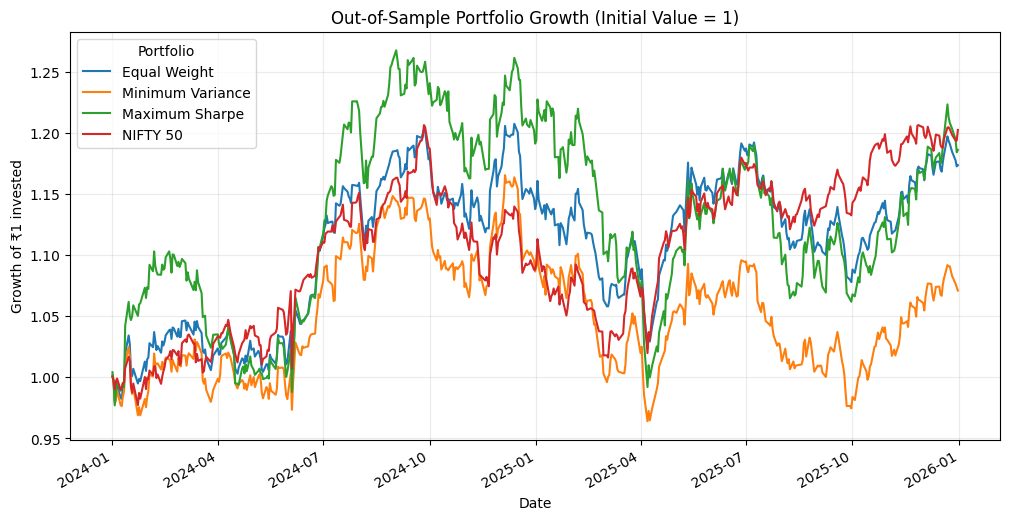

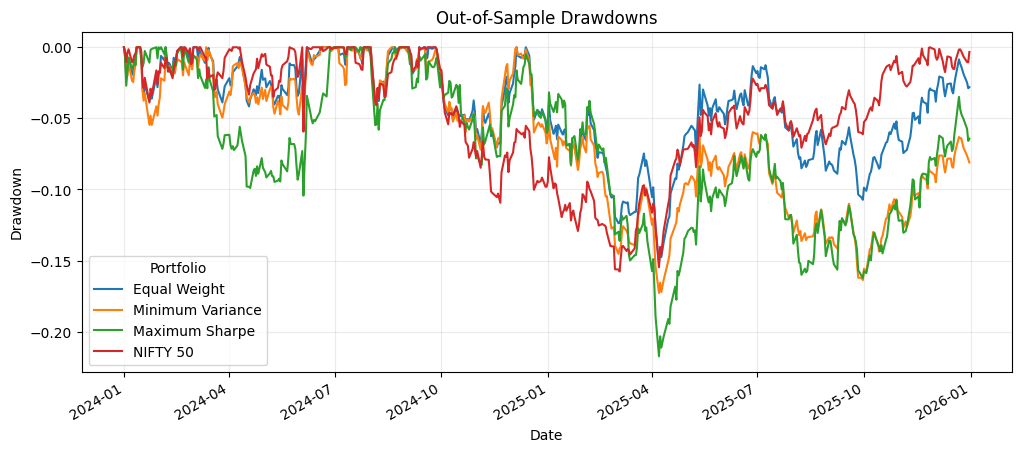

In [11]:
growth = (1 + test_portfolio_returns).cumprod()
fig, ax = plt.subplots(figsize=(12, 6))
growth.plot(ax=ax)
ax.set_title("Out-of-Sample Portfolio Growth (Initial Value = 1)")
ax.set_ylabel("Growth of ₹1 invested")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend(title="Portfolio")
plt.show()

drawdowns = growth.div(growth.cummax()).sub(1)
fig, ax = plt.subplots(figsize=(12, 5))
drawdowns.plot(ax=ax)
ax.set_title("Out-of-Sample Drawdowns")
ax.set_ylabel("Drawdown")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend(title="Portfolio")
plt.show()

## 11. Interpret the results

Use the outputs above to answer the following questions in your own words:

1. Which optimizer produced the lowest estimated training-period volatility?
2. Did the maximum-Sharpe portfolio outperform equal weighting out of sample?
3. How did out-of-sample drawdowns compare across portfolios?
4. Did any optimized portfolio concentrate heavily in one stock?
5. How sensitive might the results be to estimation error in expected returns and covariance?
6. What could change after including transaction costs and rebalancing turnover?

Do not conclude that an optimized portfolio is universally superior from one historical split. The estimates depend on the chosen assets, dates, return assumptions, and constraints.

## 12. Limitations and next steps

### Limitations
- The universe contains only five large Indian stocks, not the full market.
- Mean returns and covariance are estimated from historical data and may change over time.
- Maximum-Sharpe optimization is especially sensitive to mean-return estimates.
- The risk-free rate is an explicit assumption, not a dynamically sourced series.
- No taxes, slippage, liquidity constraints, or transaction costs are modeled.
- The constant-mix out-of-sample calculation is a simplified portfolio implementation.

### Conclusion
This notebook demonstrates how to translate estimated return and risk inputs into constrained portfolio weights, visualize the mean-variance trade-off, and test the resulting portfolios on later data. The key research question is not merely which optimizer has the highest historical return, but whether its advantage survives out-of-sample evaluation and more realistic implementation assumptions.